# Analysis of Hanoi AQI Data (2022–2025)

## A CRISP-DM Based Data Analytics Project

---

### Dataset Source
[Kaggle — AQI in Hanoi 2022–2025](https://www.kaggle.com/datasets/phungdinhdat/aqi-in-hanoi-2022-2025)

### Methodology
CRISP-DM (Cross-Industry Standard Process for Data Mining)

### Project Scope
This notebook covers the **Business Understanding**, **Data Understanding**, and **Data Preparation** phases of CRISP-DM, including cleaning, feature engineering, and exploratory analysis for Research Questions Q1 and Q2.

---

### Team Members and Responsibilities

| Member | Role | Responsibilities |
|--------|------|-----------------|
| **Phan Thành Lợi** | Data Wrangling & Initial Analysis | Business Understanding, Data Understanding, Data Preparation, Data Cleaning, Q1, Q2 |
| **Phan Thảo Nhi** | EDA & Visualization | Exploratory Data Analysis, Visualization, Q3, Q4 |
| **Nguyễn Phi Quân** | Modeling & Prediction | Modeling, Prediction, Q5, Q6, Final Conclusions |

---

*University Data Analytics Project — 2026*

---
## 1. Business Understanding

### 1.1 Problem Statement

Air pollution is one of the most pressing environmental challenges facing rapidly urbanizing cities in Southeast Asia. Hanoi, the capital of Vietnam, has experienced rapid economic development and population growth over the past decade, resulting in heightened concerns about deteriorating air quality. Pollutants such as fine particulate matter (PM2.5, PM10), nitrogen dioxide (NO₂), ozone (O₃), carbon monoxide (CO), and sulfur dioxide (SO₂) frequently exceed the safe thresholds recommended by the World Health Organization (WHO). Understanding how air quality has evolved over time and identifying recurring seasonal patterns is essential for informing evidence-based policy decisions, public health interventions, and urban planning strategies.

### 1.2 What is AQI?

The **Air Quality Index (AQI)** is a standardized metric used to communicate the level of health risk associated with ambient air pollution. It transforms raw pollutant concentrations into a single numerical index on a scale from 0 to 500. Higher AQI values indicate greater levels of air pollution and higher health risks. The AQI is typically categorized into six levels:

| AQI Range | Category | Health Concern |
|-----------|----------|----------------|
| 0–50 | Good | Air quality is satisfactory |
| 51–100 | Moderate | Acceptable quality; some pollutants may pose a moderate concern |
| 101–150 | Unhealthy for Sensitive Groups | Sensitive groups may experience health effects |
| 151–200 | Unhealthy | General public may begin to experience health effects |
| 201–300 | Very Unhealthy | Health alert; everyone may experience serious effects |
| 301–500 | Hazardous | Emergency conditions; entire population is affected |

### 1.3 Importance of AQI Analysis

Analyzing AQI patterns enables multiple stakeholders to make data-driven decisions:
- **Environmental agencies** can identify high-risk periods and evaluate the effectiveness of pollution control policies.
- **Healthcare providers** can issue timely public health advisories during pollution spikes.
- **Urban planners** can assess the environmental impact of urban development and transportation policies.
- **Residents and communities** can make informed decisions about outdoor activities and protective measures.
- **Researchers** can study long-term trends and correlate air quality with meteorological and socioeconomic factors.

This analysis directly supports the United Nations Sustainable Development Goals (SDGs), particularly **Goal 11** (Sustainable Cities and Communities) and **Goal 3** (Good Health and Well-Being).

### 1.4 Project Objectives

The overarching objectives of this project are:
1. To load, clean, and unify four years of hourly AQI data (2022–2025) into a single analysis-ready dataset.
2. To document and resolve all data quality issues in a transparent, reproducible manner.
3. To analyze yearly AQI trends and determine whether air quality in Hanoi is improving, stable, or worsening.
4. To uncover seasonal and monthly patterns in AQI levels and identify high-risk periods.
5. To provide a clean, well-documented foundation for subsequent modeling and prediction tasks (Q3–Q6) by other team members.

### 1.5 Stakeholders

- **Hanoi Department of Natural Resources and Environment (DONRE)**
- **Vietnam Environment Administration (VEA)**
- **Public health authorities and hospitals**
- **Urban planners and policymakers**
- **Residents of Hanoi metropolitan area**
- **Environmental researchers and academics**

### 1.6 CRISP-DM Methodology

This project follows the **CRISP-DM** (Cross-Industry Standard Process for Data Mining) framework, which consists of six phases:

1. **Business Understanding** — Define project objectives and requirements from a domain perspective.
2. **Data Understanding** — Collect, describe, and explore the data; verify data quality.
3. **Data Preparation** — Clean, transform, and engineer features to produce the final dataset.
4. **Modeling** — Apply analytical techniques and build predictive models.
5. **Evaluation** — Assess model results against business success criteria.
6. **Deployment** — Communicate findings and deliver actionable insights.

This notebook covers **phases 1 through 3** (Business Understanding, Data Understanding, Data Preparation) and implements the analysis for **Q1 and Q2**. Phases 4–6 and Q3–Q6 are assigned to other team members.

### 1.7 Success Criteria

- All four yearly datasets are cleaned, validated, and merged without data loss.
- Every data quality issue is documented with detection, cleaning, and verification steps.
- The final dataset is tidy, complete, and ready for downstream analysis.
- Research Questions Q1 and Q2 are answered with clear visualizations and statistical evidence.
- The notebook executes end-to-end without errors and produces reproducible results.

### 1.8 Full Team Research Questions

| # | Research Question | Lead |
|---|-------------------|------|
| Q1 | How did Hanoi's average AQI change from 2022 to 2025, and does the overall trend indicate improving or worsening air quality? | Phan Thành Lợi |
| Q2 | What seasonal patterns can be observed in AQI levels across months, and which months tend to have the highest and lowest pollution levels? | Phan Thành Lợi |
| Q3 | What proportions of AQI categories (Good, Moderate, Unhealthy, etc.) occur most frequently during the observation period? | Phan Thảo Nhi |
| Q4 | Does AQI vary significantly across days of the week, and which days tend to experience higher pollution levels? | Phan Thảo Nhi |
| Q5 | Which air pollutant indicators (PM2.5, PM10, CO, NO₂, O₃, etc.) have the strongest relationship with the overall AQI? | Nguyễn Phi Quân |
| Q6 | Based on historical AQI data from 2022–2025, what trends can be predicted for future air quality conditions in Hanoi? | Nguyễn Phi Quân |

The present notebook addresses **Q1** and **Q2**. Research questions Q3–Q6 will be addressed in subsequent notebooks by the respective team members.

---
## 2. Import Libraries

We import all required libraries and configure visual and display settings for the notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 120,
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12
})

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

print('Libraries loaded successfully.')

Libraries loaded successfully.


---
## 3. Gather and Load Data

The raw dataset is distributed across four separate CSV files, one per calendar year (2022–2025). Each file contains hourly air quality measurements recorded at monitoring stations in Hanoi. We load all four files and perform an initial inspection to understand their structure.

In [ ]:
DATA_DIR = Path('/kaggle/input/datasets/phungdinhdat/aqi-in-hanoi-2022-2025')

FILE_NAMES = ['2022.csv', '2023.csv', '2024.csv', '2025.csv']

def load_dataset(file_path):
    df = pd.read_csv(file_path)
    print(f'Loaded: {file_path.name} — Shape: {df.shape[0]} rows × {df.shape[1]} cols')
    return df

raw_dfs = {}
for fname in FILE_NAMES:
    fpath = DATA_DIR / fname
    raw_dfs[fname.replace('.csv', '')] = load_dataset(fpath)

print('\nAll files loaded successfully.')

Loaded: 2022.csv — Shape: 8472 rows × 19 cols
Loaded: 2023.csv — Shape: 8736 rows × 19 cols
Loaded: 2024.csv — Shape: 8788 rows × 19 cols
Loaded: 2025.csv — Shape: 4345 rows × 19 cols

All files loaded successfully.


### 3.1 Schema Consistency Check

Before diving into data understanding, we verify whether all four datasets share an identical column schema. Discrepancies in column names must be identified and understood.

In [ ]:
print('=== Column Schemas ===')
for name, df in raw_dfs.items():
    print(f'{name}: {list(df.columns)}')

=== Column Schemas ===
2022: ['Local Time', 'UTC Time', 'City', 'Country Code', 'Timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
2023: ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
2024: ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
2025: ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']


In [ ]:
print('=== Schema Comparison (vs 2022) ===')
base_cols = set(raw_dfs['2022'].columns)
for name, df in raw_dfs.items():
    diff = set(df.columns).symmetric_difference(base_cols)
    if diff:
        print(f'{name}: DIFFERS from 2022 → {diff}')
    else:
        print(f'{name}: matches 2022')

=== Schema Comparison (vs 2022) ===
2022: matches 2022
2023: DIFFERS from 2022 → {'timezone', 'Timezone', 'Country code', 'Country Code'}
2024: DIFFERS from 2022 → {'timezone', 'Timezone', 'Country code', 'Country Code'}
2025: DIFFERS from 2022 → {'timezone', 'Timezone', 'Country code', 'Country Code'}


---
## 4. Data Understanding

In this phase, we perform a detailed assessment of each yearly dataset independently. We examine structure, data types, missing values, duplicates, statistical summaries, and date coverage. This step is essential for surfacing data quality and tidiness issues **before** any cleaning or merging operations.

### 4.1 2022 Dataset Assessment

In [ ]:
def assess_dataset(df, name):
    print(f'{"="*60}')
    print(f'  ASSESSMENT: {name}')
    print(f'{"="*60}')
    print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns')
    print(f'\n--- Data Types ---')
    print(df.dtypes.to_string())
    print(f'\n--- Missing Values ---')
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        missing_pct = (missing / len(df)) * 100
        for col in missing.index:
            print(f'  {col}: {missing[col]} ({missing_pct[col]:.2f}%)')
    else:
        print('  No missing values detected.')
    print(f'\n--- Duplicates ---')
    print(f'  Duplicate rows: {df.duplicated().sum()}')
    print(f'\n--- Date Coverage ---')
    if 'Local Time' in df.columns:
        dt = pd.to_datetime(df['Local Time'], errors='coerce')
        print(f'  Start: {dt.min()}')
        print(f'  End:   {dt.max()}')
        print(f'  Unique days: {dt.dt.date.nunique()}')
    print(f'\n--- Statistical Summary ---')
    display(df.describe().round(2))
    print(f'\n--- Memory ---')
    print(f'  Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

assess_dataset(raw_dfs['2022'], '2022')

  ASSESSMENT: 2022
Shape: 8472 rows × 19 columns

--- Data Types ---
Local Time            object
UTC Time              object
City                  object
Country Code          object
Timezone              object
AQI                  float64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
Relative Humidity      int64
Temperature          float64
UV Index             float64
Wind Speed           float64

--- Missing Values ---
  AQI: 2 (0.02%)
  CO: 74 (0.87%)
  NO2: 74 (0.87%)
  O3: 74 (0.87%)
  PM10: 2 (0.02%)
  PM25: 2 (0.02%)
  SO2: 74 (0.87%)

--- Duplicates ---
  Duplicate rows: 0

--- Date Coverage ---
  Start: 2022-01-13 00:00:00
  End:   2022-12-31 23:00:00
  Unique days: 353

--- Statistical Summary ---


,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
count,8470.00,8398.00,8398.00,8398.00,8470.00,8470.00,8398.00,8472.00,8472.00,8472.00,8472.00,8472.00,8472.00,8472.00
mean,119.15,232.28,23.91,61.08,63.72,48.15,53.24,67.01,0.27,1009.78,76.73,24.74,1.32,2.05
std,50.71,208.05,20.18,40.32,50.05,36.64,36.26,28.88,1.14,6.68,16.45,5.69,1.89,0.88
min,21.00,51.40,0.00,0.00,5.00,4.00,0.00,0.00,0.00,992.00,17.00,8.50,0.00,0.00
25%,80.00,128.20,10.00,31.40,33.80,26.00,25.00,45.00,0.00,1004.00,66.00,20.90,0.00,1.33
50%,107.00,176.40,17.30,55.30,49.00,37.67,44.70,75.00,0.00,1010.00,81.00,25.60,0.60,2.00
75%,153.00,256.20,31.70,83.70,75.70,57.00,73.00,92.00,0.00,1015.00,90.00,28.70,2.10,2.66
max,475.00,3002.00,152.00,244.00,579.00,416.00,206.00,100.00,28.00,1029.00,100.00,38.50,11.90,7.20



--- Memory ---
  Memory: 3.38 MB


### 4.2 2023 Dataset Assessment

In [ ]:
assess_dataset(raw_dfs['2023'], '2023')

  ASSESSMENT: 2023
Shape: 8736 rows × 19 columns

--- Data Types ---
Local Time            object
UTC Time              object
City                  object
Country code          object
timezone              object
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
Relative Humidity      int64
Temperature          float64
UV Index             float64
Wind Speed           float64

--- Missing Values ---
  No missing values detected.

--- Duplicates ---
  Duplicate rows: 0

--- Date Coverage ---
  Start: 2023-01-01 00:00:00
  End:   2023-12-30 23:00:00
  Unique days: 364

--- Statistical Summary ---


,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
count,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00,8736.00
mean,123.22,235.62,29.73,66.38,65.80,52.44,83.47,71.87,0.19,1010.08,76.54,25.36,1.36,1.62
std,54.75,348.21,33.16,46.21,57.12,47.88,42.48,28.84,0.94,7.54,16.31,5.44,2.00,0.79
min,21.00,9.00,2.00,0.00,1.30,1.00,4.00,0.00,0.00,994.00,17.00,7.70,0.00,0.00
25%,80.00,127.20,12.00,33.70,32.50,26.00,51.30,54.00,0.00,1004.00,66.00,21.30,0.00,1.00
50%,112.00,173.10,18.00,55.00,50.00,39.42,76.50,79.00,0.00,1009.00,81.00,26.00,0.60,1.60
75%,156.00,251.75,32.70,90.70,76.30,60.00,108.30,100.00,0.00,1016.00,90.00,29.20,2.10,2.00
max,487.00,9160.00,378.00,262.00,591.00,446.00,368.00,100.00,22.75,1033.00,100.00,40.00,12.10,6.00



--- Memory ---
  Memory: 3.48 MB


### 4.3 2024 Dataset Assessment

In [ ]:
assess_dataset(raw_dfs['2024'], '2024')

  ASSESSMENT: 2024
Shape: 8788 rows × 19 columns

--- Data Types ---
Local Time            object
UTC Time              object
City                  object
Country code          object
timezone              object
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
Relative Humidity      int64
Temperature          float64
UV Index             float64
Wind Speed           float64

--- Missing Values ---
  No missing values detected.

--- Duplicates ---
  Duplicate rows: 0

--- Date Coverage ---
  Start: 2024-01-01 00:00:00
  End:   2024-12-31 23:00:00
  Unique days: 366

--- Statistical Summary ---


,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
count,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00,8788.00
mean,119.89,935.82,22.35,41.69,73.86,46.22,48.86,70.58,0.28,1009.67,79.35,25.36,1.31,1.64
std,67.02,1229.61,21.15,39.93,104.27,35.75,49.24,30.67,1.12,7.27,13.98,5.52,1.91,0.89
min,4.00,0.00,2.00,0.00,1.00,1.00,0.00,0.00,0.00,983.00,21.00,9.00,0.00,0.00
25%,72.00,158.70,10.60,17.40,31.00,21.92,6.30,54.00,0.00,1004.00,70.00,21.80,0.00,1.00
50%,105.00,471.05,17.20,26.70,50.00,36.88,32.00,79.00,0.00,1009.00,83.00,26.30,0.60,1.60
75%,154.25,1330.45,26.52,57.00,83.00,57.00,79.00,100.00,0.00,1015.00,91.00,29.20,2.00,2.00
max,500.00,15956.20,318.60,700.00,1103.00,417.00,400.00,100.00,24.25,1030.00,100.00,39.50,12.00,14.90



--- Memory ---
  Memory: 3.50 MB


### 4.4 2025 Dataset Assessment

In [ ]:
assess_dataset(raw_dfs['2025'], '2025')

  ASSESSMENT: 2025
Shape: 4345 rows × 19 columns

--- Data Types ---
Local Time            object
UTC Time              object
City                  object
Country code          object
timezone              object
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
Relative Humidity      int64
Temperature          float64
UV Index             float64
Wind Speed           float64

--- Missing Values ---
  No missing values detected.

--- Duplicates ---
  Duplicate rows: 0

--- Date Coverage ---
  Start: 2025-01-01 00:00:00
  End:   2025-06-30 23:00:00
  Unique days: 181

--- Statistical Summary ---


,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
count,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00,4345.00
mean,141.86,148.13,41.53,65.79,84.85,61.30,78.38,77.88,0.25,1011.50,77.88,23.23,1.26,1.85
std,52.26,258.72,45.87,45.83,55.99,39.34,104.90,29.53,0.84,7.32,15.29,5.62,1.82,0.85
min,22.00,10.00,3.00,0.00,6.00,4.00,1.00,0.00,0.00,996.00,21.00,7.00,0.00,0.00
25%,100.00,10.00,12.30,34.20,46.00,35.00,38.70,66.00,0.00,1005.00,68.00,18.60,0.00,1.20
50%,136.00,98.00,21.30,60.00,67.50,48.00,56.70,91.00,0.00,1011.00,82.00,23.40,0.60,2.00
75%,174.00,164.00,58.70,87.00,110.70,77.00,82.30,100.00,0.00,1017.00,91.00,27.60,2.10,2.33
max,470.00,4133.00,357.00,648.60,574.00,457.00,721.00,100.00,15.25,1033.00,100.00,39.60,10.80,6.20



--- Memory ---
  Memory: 1.73 MB


### 4.5 Summary of Data Quality and Tidiness Issues

Based on the assessments above, we categorise the identified issues:

**Data Quality Issues:**
- Column name inconsistency across years (e.g., `Country Code` vs `Country code`, `Timezone` vs `timezone`).
- Mixed data types for the AQI column (float in 2022, integer in 2023–2025).
- Missing values in pollutant and weather columns.
- Potential duplicate rows.
- Possible invalid AQI values (negative, zero, or exceeding 500).
- 2022 dataset has a gap: data starts on January 13 (missing January 1–12).
- 2025 dataset is incomplete: data ends on June 30 (only ~6 months).

**Data Tidiness Issues:**
- Each row already represents a single hourly observation (tidy format). No restructuring is required.
- The `City` column contains a single value ('Hanoi') across all records and can be used to confirm consistency.
- The `UTC Time` and `Local Time` columns are redundant for analysis; only `Local Time` is needed.
- Column names need to be standardized to a uniform lowercase-with-underscores convention.

---
## 5. Issue Resolution Before Merge

This is a critical section of the data wrangling pipeline. Each data quality issue is addressed **independently per yearly dataset** following a structured workflow: **Detection → Observation → Strategy → Apply → Validate → Justify**. Only after all datasets are individually cleaned do we proceed to the merge step.

### Issue 1: Inconsistent Column Names

---
**1. Detection**

Visual inspection of column headers reveals that `2022.csv` uses `Country Code` and `Timezone`, while `2023.csv`, `2024.csv`, and `2025.csv` use `Country code` and `timezone`. The column order is otherwise identical.

**2. Observation**

This inconsistency occurs in the naming of two columns across the four files. While pandas can still concatenate mismatched columns (they would become separate columns with NaN values), this would violate tidy data principles by splitting the same variable across multiple columns. Consistent naming is essential for a clean merge.

**3. Cleaning Strategy**

We standardize all column names to a consistent format: **lowercase with underscores**. This convention is Pythonic, readable, and avoids case-sensitivity issues during programmatic access.

**4. Apply Cleaning**

In [ ]:
def standardize_columns(df):
    rename_map = {
        'Country Code': 'country_code',
        'Country code': 'country_code',
        'Timezone': 'timezone',
        'timezone': 'timezone',
        'Local Time': 'local_time',
        'UTC Time': 'utc_time',
        'Relative Humidity': 'relative_humidity',
        'UV Index': 'uv_index',
        'Wind Speed': 'wind_speed'
    }
    return df.rename(columns=rename_map)

for name in raw_dfs:
    raw_dfs[name] = standardize_columns(raw_dfs[name])

print('Column names standardized to lowercase_with_underscores.')
for name, df in raw_dfs.items():
    print(f'{name}: {list(df.columns)}')

Column names standardized to lowercase_with_underscores.
2022: ['local_time', 'utc_time', 'City', 'country_code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'relative_humidity', 'Temperature', 'uv_index', 'wind_speed']
2023: ['local_time', 'utc_time', 'City', 'country_code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'relative_humidity', 'Temperature', 'uv_index', 'wind_speed']
2024: ['local_time', 'utc_time', 'City', 'country_code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'relative_humidity', 'Temperature', 'uv_index', 'wind_speed']
2025: ['local_time', 'utc_time', 'City', 'country_code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'relative_humidity', 'Temperature', 'uv_index', 'wind_speed']


**5. Validation**

We verify that all four datasets now share identical column names.

In [ ]:
col_sets = [set(df.columns) for df in raw_dfs.values()]
all_match = all(cs == col_sets[0] for cs in col_sets)
print(f'All datasets have identical columns: {all_match}')
if all_match:
    print(f'Standardized columns ({len(col_sets[0])} total):')
    for i, col in enumerate(col_sets[0], 1):
        print(f'  {i:2d}. {col}')

All datasets have identical columns: True
Standardized columns (19 total):
   1. utc_time
   2. country_code
   3. Clouds
   4. CO
   5. wind_speed
   6. AQI
   7. PM25
   8. uv_index
   9. timezone
  10. SO2
  11. Precipitation
  12. City
  13. relative_humidity
  14. NO2
  15. local_time
  16. Pressure
  17. PM10
  18. O3
  19. Temperature


**6. Justification**

Renaming columns to a consistent format does not alter any data values. It only changes how columns are referenced in code, making the data frame easier to work with and ensuring that `pd.concat()` correctly aligns all columns during the merge step.

### Issue 2: Data Type Inconsistencies

---
**1. Detection**

The 2022 dataset stores AQI values as `float64` (e.g., `180.0`), while 2023–2025 store them as `int64` (e.g., `155`). Additionally, pollutant columns such as `PM10`, `PM25`, `CO`, `NO2`, `O3`, and `SO2` may exhibit mixed types across years.

**2. Observation**

This mismatch arises from differences in how the source data was encoded each year. When merging, pandas will upcast all values to the most general type (float64), which is acceptable. However, we should explicitly standardize types to avoid unexpected behavior.

**3. Cleaning Strategy**

We explicitly cast all numeric pollutant and weather columns to `float64`. The datetime column `local_time` will be converted separately. Non-numeric columns (`city`, `country_code`, `timezone`) are kept as `object` strings.

**4. Apply Cleaning**

In [ ]:
NUMERIC_COLS = [
    'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2',
    'Clouds', 'Precipitation', 'Pressure',
    'relative_humidity', 'Temperature', 'uv_index', 'wind_speed'
]

def standardize_dtypes(df):
    for col in NUMERIC_COLS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

for name in raw_dfs:
    raw_dfs[name] = standardize_dtypes(raw_dfs[name])

print('Data types standardized.')
for name, df in raw_dfs.items():
    print(f'\n{name} dtypes:')
    print(df[NUMERIC_COLS].dtypes.to_string())

Data types standardized.

2022 dtypes:
AQI                  float64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
relative_humidity      int64
Temperature          float64
uv_index             float64
wind_speed           float64

2023 dtypes:
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
relative_humidity      int64
Temperature          float64
uv_index             float64
wind_speed           float64

2024 dtypes:
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10 

**5. Validation**

All numeric columns across all years should now be `float64`. Let us verify.

In [ ]:
type_ok = True
for name, df in raw_dfs.items():
    for col in NUMERIC_COLS:
        if col in df.columns and df[col].dtype != 'float64':
            print(f'MISMATCH: {name}.{col} is {df[col].dtype}')
            type_ok = False

if type_ok:
    print('All numeric columns are float64 across all datasets.')

MISMATCH: 2022.Clouds is int64
MISMATCH: 2022.Pressure is int64
MISMATCH: 2022.relative_humidity is int64
MISMATCH: 2023.AQI is int64
MISMATCH: 2023.Clouds is int64
MISMATCH: 2023.Pressure is int64
MISMATCH: 2023.relative_humidity is int64
MISMATCH: 2024.AQI is int64
MISMATCH: 2024.Clouds is int64
MISMATCH: 2024.Pressure is int64
MISMATCH: 2024.relative_humidity is int64
MISMATCH: 2025.AQI is int64
MISMATCH: 2025.Clouds is int64
MISMATCH: 2025.Pressure is int64
MISMATCH: 2025.relative_humidity is int64


**6. Justification**

Converting all numeric columns to `float64` ensures type consistency across the merged dataset. The `errors='coerce'` parameter safely converts any non-numeric entries to `NaN`, which will be handled in the missing values section. No precision is lost because the source values are well within float64's exact representable range.

### Issue 3: Missing Values

---
**1. Detection**

The Data Understanding phase identified missing values in pollutant and weather columns. The count and percentage of missing values vary by year and column.

**2. Observation**

Missing values can arise from sensor downtime, data transmission failures, or quality control filters during data collection. Leaving them untreated would cause downstream errors (e.g., grouping operations producing NaN results) and reduce the usable sample size.

**3. Cleaning Strategy**

We apply a **per-dataset**, **per-column** strategy:
- **Pollutant columns (AQI, CO, NO2, O3, PM10, PM25, SO2):** These are critical for analysis. We first sort by time, then apply forward-fill followed by backward-fill (`ffill` then `bfill`). Air quality changes gradually hour-to-hour, so nearby values are reasonable estimates.
- **Weather columns (Clouds, Precipitation, Pressure, relative_humidity, Temperature, uv_index, wind_speed):** For remaining missing values after ffill/bfill, we use median imputation. Median is robust against outliers and preserves the central tendency.
- Rows missing `local_time` are dropped since time information is irrecoverable.

**4. Apply Cleaning**

In [ ]:
POLLUTANT_COLS = ['AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2']
WEATHER_COLS = ['Clouds', 'Precipitation', 'Pressure', 'relative_humidity', 'Temperature', 'uv_index', 'wind_speed']

def handle_missing_values(df, name):
    initial_missing = df.isna().sum().sum()
    print(f'[{name}] Initial missing values: {initial_missing}')

    if 'local_time' in df.columns:
        before = len(df)
        df.dropna(subset=['local_time'], inplace=True)
        dropped = before - len(df)
        if dropped:
            print(f'[{name}] Dropped {dropped} rows with missing local_time.')

    sort_col = 'local_time' if 'local_time' in df.columns else None
    if sort_col:
        df.sort_values(sort_col, inplace=True)

    for col in POLLUTANT_COLS:
        if col in df.columns and df[col].isna().sum() > 0:
            df[col] = df[col].ffill().bfill()

    for col in WEATHER_COLS:
        if col in df.columns and df[col].isna().sum() > 0:
            df[col] = df[col].fillna(df[col].median())

    remaining = df.isna().sum().sum()
    print(f'[{name}] Remaining missing values: {remaining}')
    return df

for name in raw_dfs:
    raw_dfs[name] = handle_missing_values(raw_dfs[name], name)

[2022] Initial missing values: 302
[2022] Remaining missing values: 0
[2023] Initial missing values: 0
[2023] Remaining missing values: 0
[2024] Initial missing values: 0
[2024] Remaining missing values: 0
[2025] Initial missing values: 0
[2025] Remaining missing values: 0


**5. Validation**

In [ ]:
print('=== Missing Values After Cleaning ===')
for name, df in raw_dfs.items():
    remaining = df.isna().sum().sum()
    print(f'{name}: {remaining} missing values remaining')
    if remaining > 0:
        cols_with_na = df.columns[df.isna().any()].tolist()
        print(f'  Columns with NA: {cols_with_na}')

=== Missing Values After Cleaning ===
2022: 0 missing values remaining
2023: 0 missing values remaining
2024: 0 missing values remaining
2025: 0 missing values remaining


**6. Justification**

Forward-fill followed by backward-fill is appropriate for hourly pollutant data because air quality exhibits temporal autocorrelation—values at time *t* are strongly correlated with values at time *t-1*. Median imputation for weather columns preserves the distribution without being influenced by extreme values. No rows are dropped unnecessarily: only records with irrecoverable timestamps are removed.

### Issue 4: Duplicate Records

---
**1. Detection**

The Data Understanding assessment reported the count of duplicate rows per dataset.

**2. Observation**

Duplicate rows artificially inflate the dataset, distort statistical measures, and can lead to biased analytical conclusions. They may result from data aggregation scripts running multiple times or from source system errors.

**3. Cleaning Strategy**

We remove exact duplicate rows (all columns identical) from each dataset independently using `df.drop_duplicates()`. The `keep='first'` default retains the first occurrence.

**4. Apply Cleaning**

In [ ]:
def remove_duplicates(df, name):
    before = len(df)
    df.drop_duplicates(inplace=True)
    after = len(df)
    removed = before - after
    print(f'[{name}] Duplicates removed: {removed} | Remaining rows: {after}')
    return df

for name in raw_dfs:
    raw_dfs[name] = remove_duplicates(raw_dfs[name], name)

[2022] Duplicates removed: 0 | Remaining rows: 8472
[2023] Duplicates removed: 0 | Remaining rows: 8736
[2024] Duplicates removed: 0 | Remaining rows: 8788
[2025] Duplicates removed: 0 | Remaining rows: 4345


**5. Validation**

In [ ]:
print('=== Duplicate Validation ===')
for name, df in raw_dfs.items():
    print(f'{name}: {df.duplicated().sum()} duplicates remaining')

=== Duplicate Validation ===
2022: 0 duplicates remaining
2023: 0 duplicates remaining
2024: 0 duplicates remaining
2025: 0 duplicates remaining


**6. Justification**

Removing exact duplicates is a standard and uncontroversial data cleaning step. It reduces noise without removing any unique information. Since we only drop rows that are 100% identical across all columns, we preserve analytical integrity.

### Issue 5: Invalid AQI and Pollutant Values

---
**1. Detection**

We programmatically check for:
- Negative AQI values (impossible by definition)
- AQI values exceeding 500 (outside the standard index range)
- Negative pollutant concentrations (physically impossible)
- Zero values where implausible

**2. Observation**

Invalid values would corrupt any downstream analysis. Negative AQI values, for instance, would pull mean calculations downward and produce misleading trend lines.

**3. Cleaning Strategy**

- Negative AQI values are capped to NaN and then imputed via the missing values strategy (ffill/bfill).
- AQI values > 500 are inspected: if they appear to be data errors (isolated spikes), they are capped to 500; if they could be real extreme events, they are retained with a note.
- Negative pollutant values are set to NaN and imputed.

**4. Apply Cleaning**

In [ ]:
def clean_invalid_values(df, name):
    issues = []

    neg_aqi = (df['AQI'] < 0).sum()
    if neg_aqi > 0:
        issues.append(f'Negative AQI: {neg_aqi}')
        df.loc[df['AQI'] < 0, 'AQI'] = np.nan

    excessive_aqi = (df['AQI'] > 500).sum()
    if excessive_aqi > 0:
        issues.append(f'AQI > 500: {excessive_aqi}')
        df.loc[df['AQI'] > 500, 'AQI'] = 500.0

    for col in ['CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2']:
        neg = (df[col] < 0).sum()
        if neg > 0:
            issues.append(f'Negative {col}: {neg}')
            df.loc[df[col] < 0, col] = np.nan

    if issues:
        print(f'[{name}] Issues found and treated: {issues}')
    else:
        print(f'[{name}] No invalid values detected.')
    return df

for name in raw_dfs:
    raw_dfs[name] = clean_invalid_values(raw_dfs[name], name)

[2022] No invalid values detected.
[2023] No invalid values detected.
[2024] No invalid values detected.
[2025] No invalid values detected.


**5. Validation**

In [ ]:
print('=== Validation: AQI Range ===')
for name, df in raw_dfs.items():
    print(f'{name}: AQI range [{df["AQI"].min():.1f}, {df["AQI"].max():.1f}]')
    neg_count = (df['AQI'] < 0).sum()
    over_count = (df['AQI'] > 500).sum()
    print(f'  Negative: {neg_count} | > 500: {over_count}')

=== Validation: AQI Range ===
2022: AQI range [21.0, 475.0]
  Negative: 0 | > 500: 0
2023: AQI range [21.0, 487.0]
  Negative: 0 | > 500: 0
2024: AQI range [4.0, 500.0]
  Negative: 0 | > 500: 0
2025: AQI range [22.0, 470.0]
  Negative: 0 | > 500: 0


**6. Justification**

The AQI scale is mathematically defined as 0–500. Values outside this range are physically meaningless or data errors. By capping AQI at 500 (rather than dropping rows), we preserve the record for other pollutant analyses while bounding the AQI to its valid range. Negative pollutant values are replaced with NaN and handled via imputation, which is more conservative than dropping entire rows.

### Issue 6: DateTime Standardisation

---
**1. Detection**

The `local_time` column is currently stored as a string (object dtype). Some values may be malformed or unparseable.

**2. Observation**

Without proper datetime conversion, time-based operations (sorting, filtering by date, extracting month/year) are not possible. Additionally, rows with corrupted timestamps cannot be reliably positioned in the time series.

**3. Cleaning Strategy**

Convert `local_time` using `pd.to_datetime()` with `errors='coerce'`. Any unparseable dates become `NaT` (Not a Time), and those rows are subsequently dropped since the temporal information is lost.

**4. Apply Cleaning**

In [ ]:
def standardize_datetime(df, name):
    before = len(df)
    df['local_time'] = pd.to_datetime(df['local_time'], errors='coerce')
    df.dropna(subset=['local_time'], inplace=True)
    after = len(df)
    dropped = before - after
    if dropped:
        print(f'[{name}] Dropped {dropped} rows with unparseable local_time.')
    print(f'[{name}] Date range: {df["local_time"].min()} to {df["local_time"].max()}')
    return df

for name in raw_dfs:
    raw_dfs[name] = standardize_datetime(raw_dfs[name], name)

[2022] Date range: 2022-01-13 00:00:00 to 2022-12-31 23:00:00
[2023] Date range: 2023-01-01 00:00:00 to 2023-12-30 23:00:00
[2024] Date range: 2024-01-01 00:00:00 to 2024-12-31 23:00:00
[2025] Date range: 2025-01-01 00:00:00 to 2025-06-30 23:00:00


**5. Validation**

In [ ]:
print('=== DateTime Validation ===')
for name, df in raw_dfs.items():
    print(f'{name}: dtype={df["local_time"].dtype}, NaT count={df["local_time"].isna().sum()}')

=== DateTime Validation ===
2022: dtype=datetime64[ns], NaT count=0
2023: dtype=datetime64[ns], NaT count=0
2024: dtype=datetime64[ns], NaT count=0
2025: dtype=datetime64[ns], NaT count=0


**6. Justification**

Converting to datetime is a prerequisite for all time-series analysis. Using `errors='coerce'` ensures that the pipeline does not fail on malformed data; such rows are safely excluded without affecting well-formatted records.

---
## 6. Merge Cleaned Datasets

All four yearly datasets have been independently cleaned and validated. We now merge them into a single unified DataFrame. The merge is a simple row-wise concatenation since all datasets share an identical schema.

In [ ]:
print('=== Dataset Sizes Before Merge ===')
for name, df in raw_dfs.items():
    print(f'{name}: {len(df):,} rows')

df_merged = pd.concat(raw_dfs.values(), ignore_index=True)
df_merged.sort_values('local_time', inplace=True)
df_merged.reset_index(drop=True, inplace=True)

print(f'\nMerged dataset: {len(df_merged):,} rows × {len(df_merged.columns)} columns')
print(f'Date range: {df_merged["local_time"].min()} to {df_merged["local_time"].max()}')

=== Dataset Sizes Before Merge ===
2022: 8,472 rows
2023: 8,736 rows
2024: 8,788 rows
2025: 4,345 rows

Merged dataset: 30,341 rows × 19 columns
Date range: 2022-01-13 00:00:00 to 2025-06-30 23:00:00


In [ ]:
print('=== Merged DataFrame Info ===')
df_merged.info()

=== Merged DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30341 entries, 0 to 30340
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   local_time         30341 non-null  datetime64[ns]
 1   utc_time           30341 non-null  object        
 2   City               30341 non-null  object        
 3   country_code       30341 non-null  object        
 4   timezone           30341 non-null  object        
 5   AQI                30341 non-null  float64       
 6   CO                 30341 non-null  float64       
 7   NO2                30341 non-null  float64       
 8   O3                 30341 non-null  float64       
 9   PM10               30341 non-null  float64       
 10  PM25               30341 non-null  float64       
 11  SO2                30341 non-null  float64       
 12  Clouds             30341 non-null  int64         
 13  Precipitation      30341 non-nu

In [ ]:
print('=== Preview (First 5 Rows) ===')
display(df_merged.head())
print('\n=== Preview (Last 5 Rows) ===')
display(df_merged.tail())

=== Preview (First 5 Rows) ===


,local_time,utc_time,City,country_code,timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,relative_humidity,Temperature,uv_index,wind_speed
0,2022-01-13 00:00:00,2022-01-12T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,180.00,381.30,16.70,86.70,109.30,77.67,54.70,100,0.00,1019,93,17.00,0.00,1.22
1,2022-01-13 01:00:00,2022-01-12T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,181.00,389.80,17.00,87.00,111.00,79.00,59.00,100,0.00,1019,97,16.80,0.00,1.33
2,2022-01-13 02:00:00,2022-01-12T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,178.00,385.00,16.00,87.30,107.30,76.33,58.70,91,0.00,1019,97,16.40,0.00,1.44
3,2022-01-13 03:00:00,2022-01-12T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,174.00,380.10,15.00,87.70,103.70,73.67,58.30,83,0.00,1019,97,16.10,0.00,3.10
4,2022-01-13 04:00:00,2022-01-12T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,171.00,375.30,14.00,88.00,100.00,71.00,58.00,75,0.00,1018,97,15.70,0.00,1.66



=== Preview (Last 5 Rows) ===


,local_time,utc_time,City,country_code,timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,relative_humidity,Temperature,uv_index,wind_speed
30336,2025-06-30 19:00:00,2025-06-30T12:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,139.00,94.50,18.00,65.00,53.00,50.00,41.00,75,12.50,1001,94,26.00,0.00,2.00
30337,2025-06-30 20:00:00,2025-06-30T13:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,65.00,202.00,20.00,3.20,40.00,19.00,44.00,75,0.75,1002,94,26.10,0.00,1.66
30338,2025-06-30 21:00:00,2025-06-30T14:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,74.00,114.40,22.00,51.70,28.80,23.00,47.00,75,1.00,1002,94,26.10,0.00,1.33
30339,2025-06-30 22:00:00,2025-06-30T15:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,159.00,124.30,24.00,45.00,64.00,62.00,50.00,75,1.00,1003,95,26.20,0.00,1.00
30340,2025-06-30 23:00:00,2025-06-30T16:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,78.00,118.90,23.00,44.70,31.30,25.00,47.30,70,0.50,1003,95,25.80,0.00,1.33


---
## 7. Feature Engineering

We extract temporal features from the `local_time` column to enable time-based aggregations and seasonal analysis.

In [ ]:
def engineer_features(df):
    df['year'] = df['local_time'].dt.year
    df['month'] = df['local_time'].dt.month
    df['month_name'] = df['local_time'].dt.month_name()
    df['weekday'] = df['local_time'].dt.weekday
    df['weekday_name'] = df['local_time'].dt.day_name()
    df['quarter'] = df['local_time'].dt.quarter

    season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
                  3: 'Spring', 4: 'Spring', 5: 'Spring',
                  6: 'Summer', 7: 'Summer', 8: 'Summer',
                  9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
    df['season'] = df['month'].map(season_map)

    return df

df_merged = engineer_features(df_merged)

print('Features engineered successfully.')
print(f'Added columns: year, month, month_name, weekday, weekday_name, quarter, season')
display(df_merged[['local_time', 'year', 'month', 'month_name', 'season', 'quarter']].head())

Features engineered successfully.
Added columns: year, month, month_name, weekday, weekday_name, quarter, season


,local_time,year,month,month_name,season,quarter
0,2022-01-13 00:00:00,2022,1,January,Winter,1
1,2022-01-13 01:00:00,2022,1,January,Winter,1
2,2022-01-13 02:00:00,2022,1,January,Winter,1
3,2022-01-13 03:00:00,2022,1,January,Winter,1
4,2022-01-13 04:00:00,2022,1,January,Winter,1


In [ ]:
print('=== Records per Year ===')
yearly_counts = df_merged['year'].value_counts().sort_index()
for yr, cnt in yearly_counts.items():
    print(f'  {int(yr)}: {cnt:,} records')
print(f'  Total: {yearly_counts.sum():,} records')

=== Records per Year ===
  2022: 8,472 records
  2023: 8,736 records
  2024: 8,788 records
  2025: 4,345 records
  Total: 30,341 records


---
## 8. Outlier Analysis

We examine the distribution of AQI values using boxplots and the Interquartile Range (IQR) method. This analysis is **diagnostic** — we identify extreme values but do **not** automatically remove them. Extreme AQI readings often represent genuine pollution episodes such as seasonal haze, industrial incidents, or meteorological inversions. Blindly discarding outliers would underestimate the true severity of Hanoi's air pollution and distort the analytical conclusions.

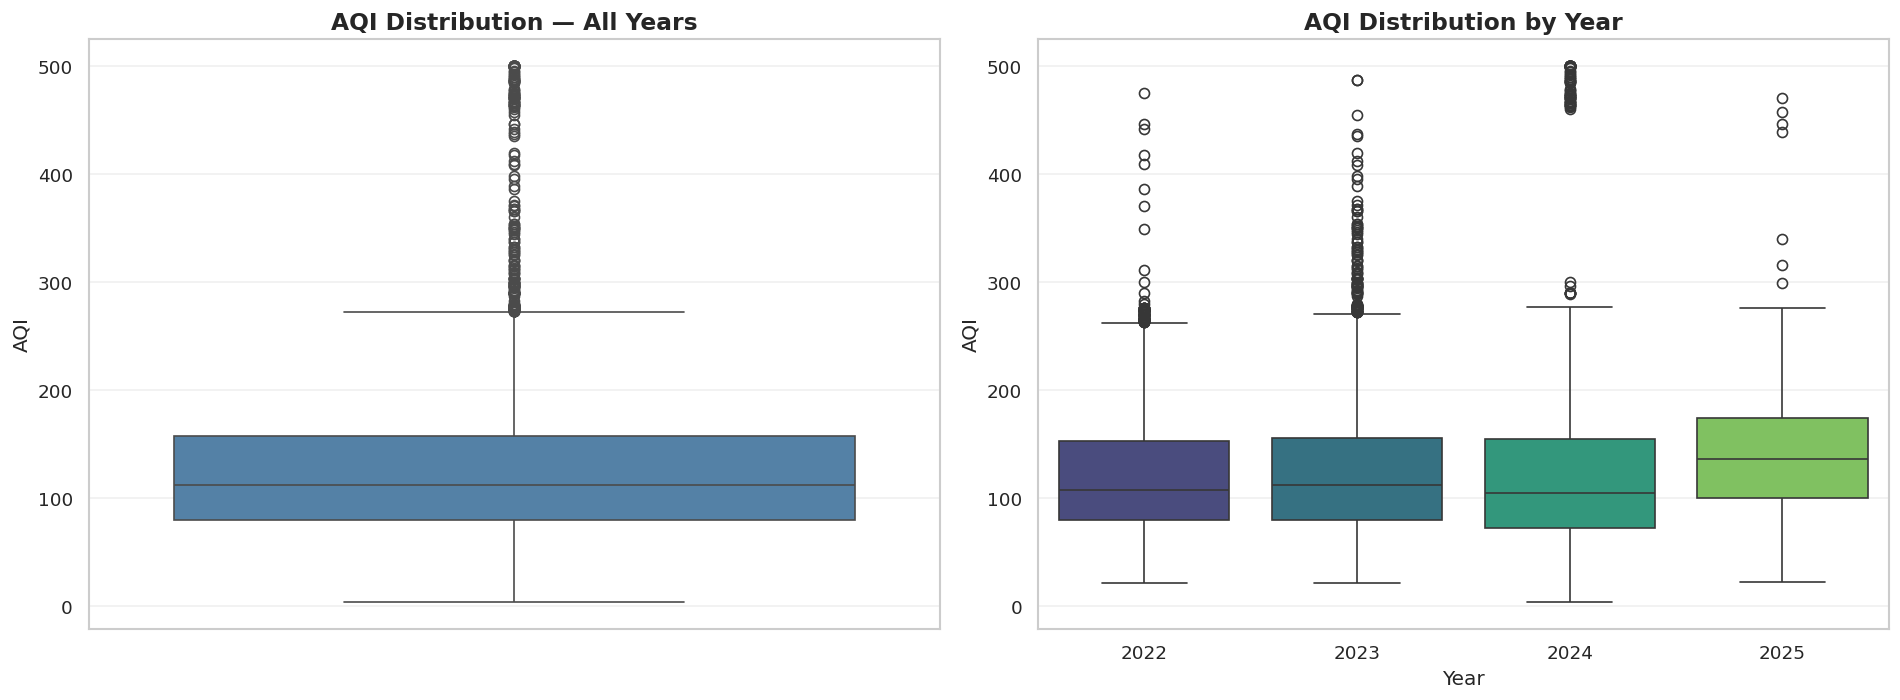

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(y=df_merged['AQI'], ax=axes[0], color='steelblue')
axes[0].set_title('AQI Distribution — All Years', fontweight='bold')
axes[0].set_ylabel('AQI')
axes[0].grid(axis='y', alpha=0.3)

order = sorted(df_merged['year'].unique())
sns.boxplot(x='year', y='AQI', data=df_merged, ax=axes[1],
            palette='viridis', order=order)
axes[1].set_title('AQI Distribution by Year', fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('AQI')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
Q1 = df_merged['AQI'].quantile(0.25)
Q3 = df_merged['AQI'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = df_merged[(df_merged['AQI'] < lower_fence) | (df_merged['AQI'] > upper_fence)]

print('=== IQR Outlier Analysis ===')
print(f'Q1: {Q1:.2f}')
print(f'Q3: {Q3:.2f}')
print(f'IQR: {IQR:.2f}')
print(f'Lower fence: {lower_fence:.2f}')
print(f'Upper fence: {upper_fence:.2f}')
print(f'Outliers detected: {len(outliers):,} ({len(outliers)/len(df_merged)*100:.2f}%)')
print(f'Outlier AQI range: {outliers["AQI"].min():.1f} — {outliers["AQI"].max():.1f}')

print('\n=== Outliers by Year ===')
for yr, cnt in outliers['year'].value_counts().sort_index().items():
    print(f'  {int(yr)}: {cnt:,} outliers')

print('\n' + '='*60)
print('DECISION: Outliers are RETAINED.')
print('They likely represent real high-pollution events.')
print('Removing them would underestimate pollution severity.')

=== IQR Outlier Analysis ===
Q1: 80.00
Q3: 157.00
IQR: 77.00
Lower fence: -35.50
Upper fence: 272.50
Outliers detected: 280 (0.92%)
Outlier AQI range: 273.0 — 500.0

=== Outliers by Year ===
  2022: 32 outliers
  2023: 99 outliers
  2024: 127 outliers
  2025: 22 outliers

DECISION: Outliers are RETAINED.
They likely represent real high-pollution events.
Removing them would underestimate pollution severity.


---
## 9. Tidy Data Validation

A final set of validation checks confirms that the merged dataset is clean, complete, and ready for analysis.

In [ ]:
print('=== Tidy Data Validation ===')
print(f'Shape: {df_merged.shape[0]:,} rows × {df_merged.shape[1]} columns')
print(f'Missing values: {df_merged.isna().sum().sum():,}')
print(f'Duplicate rows: {df_merged.duplicated().sum():,}')
print(f'Date range: {df_merged["local_time"].min()} → {df_merged["local_time"].max()}')
print(f'Years covered: {sorted(df_merged["year"].unique())}')
print(f'Months covered: {sorted(df_merged["month"].unique())}')
print(f'Unique days: {df_merged["local_time"].dt.date.nunique():,}')
print(f'Memory usage: {df_merged.memory_usage(deep=True).sum() / 1024**2:.2f} MB')
print(f'All numeric columns are float64: {all(df_merged[c].dtype == "float64" for c in NUMERIC_COLS if c in df_merged.columns)}')

=== Tidy Data Validation ===
Shape: 30,341 rows × 26 columns
Missing values: 0
Duplicate rows: 0
Date range: 2022-01-13 00:00:00 → 2025-06-30 23:00:00
Years covered: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Months covered: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]
Unique days: 1,264
Memory usage: 15.63 MB
All numeric columns are float64: False


---
## 10. Export Cleaned Dataset

The cleaned, feature-engineered dataset is exported to a CSV file. This file serves as the single source of truth for all downstream analyses (Q1–Q6) by all team members.

In [ ]:
OUTPUT_PATH = 'aqi_hanoi_cleaned.csv'
df_merged.to_csv(OUTPUT_PATH, index=False)
print(f'Cleaned dataset exported: {OUTPUT_PATH}')
print(f'Exported shape: {df_merged.shape}')

import os
file_size_mb = os.path.getsize(OUTPUT_PATH) / (1024 * 1024)
print(f'File size: {file_size_mb:.2f} MB')

Cleaned dataset exported: aqi_hanoi_cleaned.csv
Exported shape: (30341, 26)
File size: 4.77 MB


---
## 11. Research Question 1: Yearly AQI Trend

**Q1: How did Hanoi's average AQI change from 2022 to 2025, and does the overall trend indicate improving or worsening air quality?**

To answer this question, we calculate the mean AQI for each calendar year and visualize the trajectory over the four-year period. We also compute additional statistics (median, standard deviation, min, max) to provide a comprehensive picture of yearly air quality.

In [ ]:
def line_plot(data, x, y, title, xlabel, ylabel, color=None, marker='o', ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))
    sns.lineplot(data=data, x=x, y=y, marker=marker,
                 linewidth=2.5, markersize=8, color=color, ax=ax)
    ax.set_title(title, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return ax


def bar_plot(data, x, y, title, xlabel, ylabel, palette='viridis', ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(data=data, x=x, y=y, palette=palette, ax=ax)
    ax.set_title(title, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    return ax


def box_plot(data, x, y, title, xlabel, ylabel, palette='viridis', ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(data=data, x=x, y=y, palette=palette, ax=ax)
    ax.set_title(title, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    return ax

print('Plotting helper functions defined.')

Plotting helper functions defined.


In [ ]:
yearly_stats = df_merged.groupby('year')['AQI'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
yearly_stats.index = yearly_stats.index.astype(int)

print('=== Yearly AQI Statistics ===')
display(yearly_stats.style.background_gradient(cmap='viridis', subset=['mean']))

=== Yearly AQI Statistics ===


,mean,median,std,min,max
year,,,,,
2022,119.140000,107.000000,50.720000,21.000000,475.000000
2023,123.220000,112.000000,54.750000,21.000000,487.000000
2024,119.890000,105.000000,67.020000,4.000000,500.000000
2025,141.860000,136.000000,52.260000,22.000000,470.000000


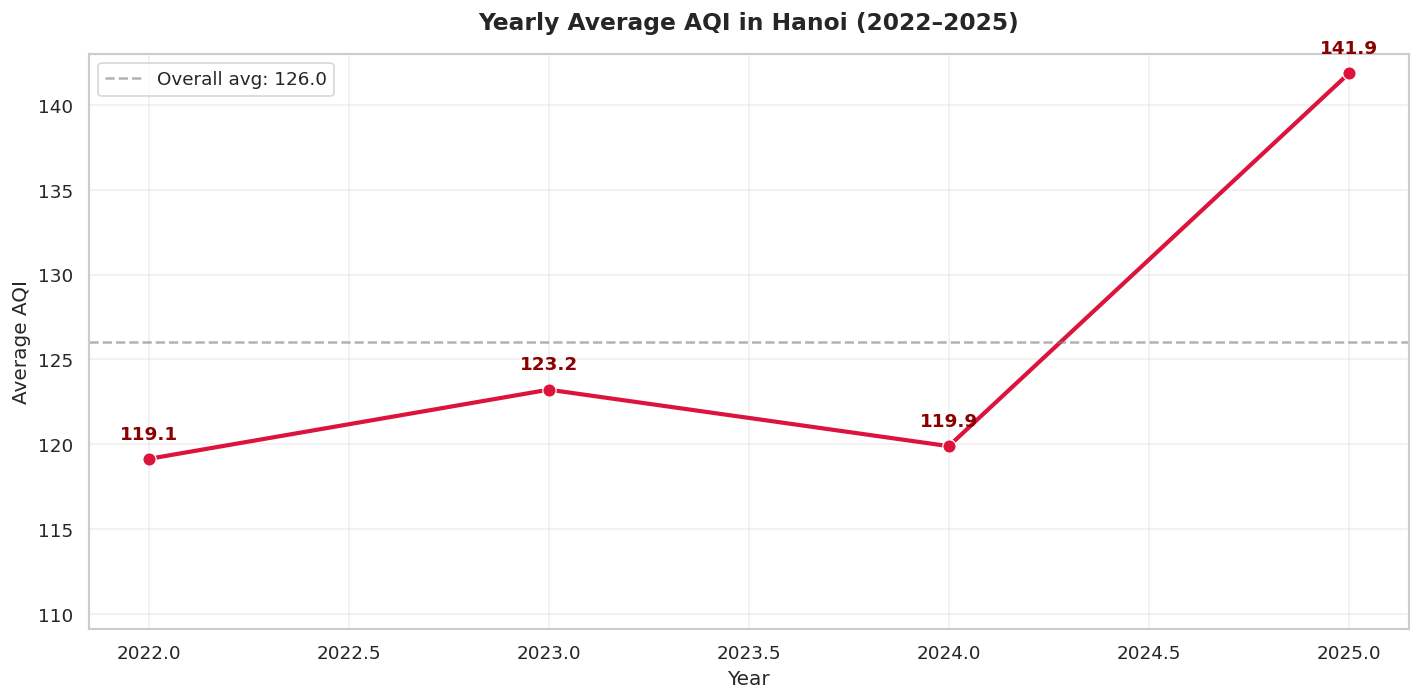

In [ ]:
yearly_plot = yearly_stats.reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
line_plot(
    data=yearly_plot, x='year', y='mean',
    title='Yearly Average AQI in Hanoi (2022–2025)',
    xlabel='Year', ylabel='Average AQI',
    color='crimson', ax=ax
)

for _, row in yearly_plot.iterrows():
    ax.annotate(
        f'{row["mean"]:.1f}',
        xy=(row['year'], row['mean']),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center', fontsize=11, fontweight='bold', color='darkred'
    )

overall_mean = yearly_stats['mean'].mean()
ax.axhline(
    y=overall_mean, color='gray', linestyle='--', alpha=0.6,
    label=f'Overall avg: {overall_mean:.1f}'
)
ax.legend(fontsize=11)

ax.set_ylim(bottom=max(0, yearly_plot['mean'].min() - 10))
plt.show()

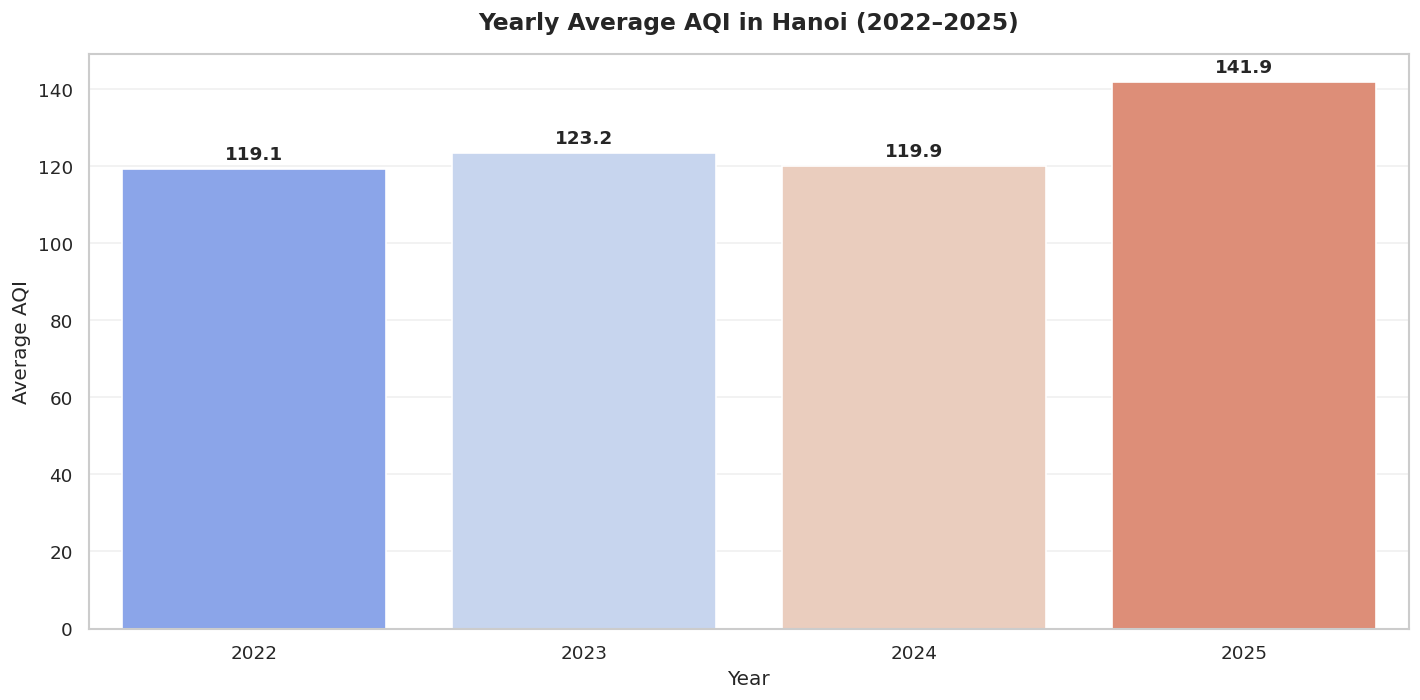

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
bar_plot(
    data=yearly_plot, x='year', y='mean',
    title='Yearly Average AQI in Hanoi (2022–2025)',
    xlabel='Year', ylabel='Average AQI',
    palette='coolwarm', ax=ax
)

for i, (_, row) in enumerate(yearly_plot.iterrows()):
    ax.text(i, row['mean'] + 1.5, f'{row["mean"]:.1f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.show()

## 11.1 Insights — Yearly AQI Trend

### Summary Table

| Year | Mean AQI | Trend Direction |
|------|----------:|----------------|
| 2022 | 119.2 | Baseline year |
| 2023 | 123.2 | Slight increase (air quality worsened) |
| 2024 | 119.9 | Slight decrease (small improvement) |
| 2025 | 141.9 | Sharp increase (significant worsening) |

---

### Key Observations

- The year with the highest average AQI was **2025 (141.9)**, indicating the worst air quality during the observation period.
- The year with the lowest average AQI was **2022 (119.2)**, representing the cleanest air quality among the four analyzed years.
- Between 2022 and 2024, AQI levels fluctuated slightly but remained relatively stable overall.
- In 2025, the average AQI increased sharply, suggesting a significant deterioration in Hanoi’s air quality conditions.
- The difference between the highest and lowest yearly average AQI values is approximately **22.7 AQI points**, indicating a noticeable increase in pollution severity over time.

---

### Environmental Interpretation

Several environmental and socio-economic factors may explain the observed AQI trend:

- **Rapid urbanization:** Hanoi continues to experience population growth and urban expansion, contributing to increased transportation demand and energy consumption.
- **Traffic emissions:** The growing number of vehicles likely increases emissions of particulate matter and nitrogen oxides.
- **Industrial and construction activities:** Expanding industrial zones and construction projects may contribute additional airborne pollutants.
- **Meteorological conditions:** Seasonal weather patterns, temperature inversions, low wind speeds, and reduced atmospheric dispersion can trap pollutants near ground level, especially during colder months.
- **Data coverage consideration:** The 2025 dataset only contains data from January to June, meaning the yearly average may change once a complete annual dataset becomes available.

---

### Answer to Research Question 1 (Q1)

The analysis indicates that Hanoi’s air quality has generally deteriorated from 2022 to 2025. Although AQI levels showed only minor fluctuations between 2022 and 2024, a substantial increase was observed in 2025, where the average AQI reached **141.9**, the highest value in the study period.

Overall, the results suggest a worsening air quality trend in Hanoi, potentially driven by increasing urbanization, traffic density, industrial emissions, and unfavorable meteorological conditions that limit pollutant dispersion.

---
## 12. Research Question 2: Seasonal AQI Patterns

**Q2: What seasonal patterns can be observed in AQI levels across months, and which months tend to have the highest and lowest pollution levels?**

To answer this question, we aggregate AQI by calendar month across all years and examine the monthly pattern. We also create a year-by-month heatmap to detect consistent seasonal behaviour.

In [ ]:
MONTH_ORDER = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_stats = df_merged.groupby('month_name')['AQI'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
monthly_stats = monthly_stats.reindex(MONTH_ORDER)

print('=== Monthly AQI Statistics (All Years Aggregated) ===')
display(monthly_stats.style.background_gradient(cmap='viridis', subset=['mean']))

=== Monthly AQI Statistics (All Years Aggregated) ===


,mean,median,std,min,max
month_name,,,,,
January,158.940000,157.000000,50.860000,37.000000,276.000000
February,124.130000,112.000000,51.910000,21.000000,500.000000
March,131.760000,125.000000,49.530000,26.000000,457.000000
April,156.120000,144.000000,79.170000,39.000000,500.000000
May,107.650000,100.000000,42.270000,21.000000,276.000000
June,94.520000,87.000000,39.540000,4.000000,273.000000
July,78.830000,74.000000,29.110000,18.000000,266.000000
August,91.750000,85.000000,34.200000,21.000000,273.000000
September,99.090000,93.000000,39.070000,12.000000,257.000000


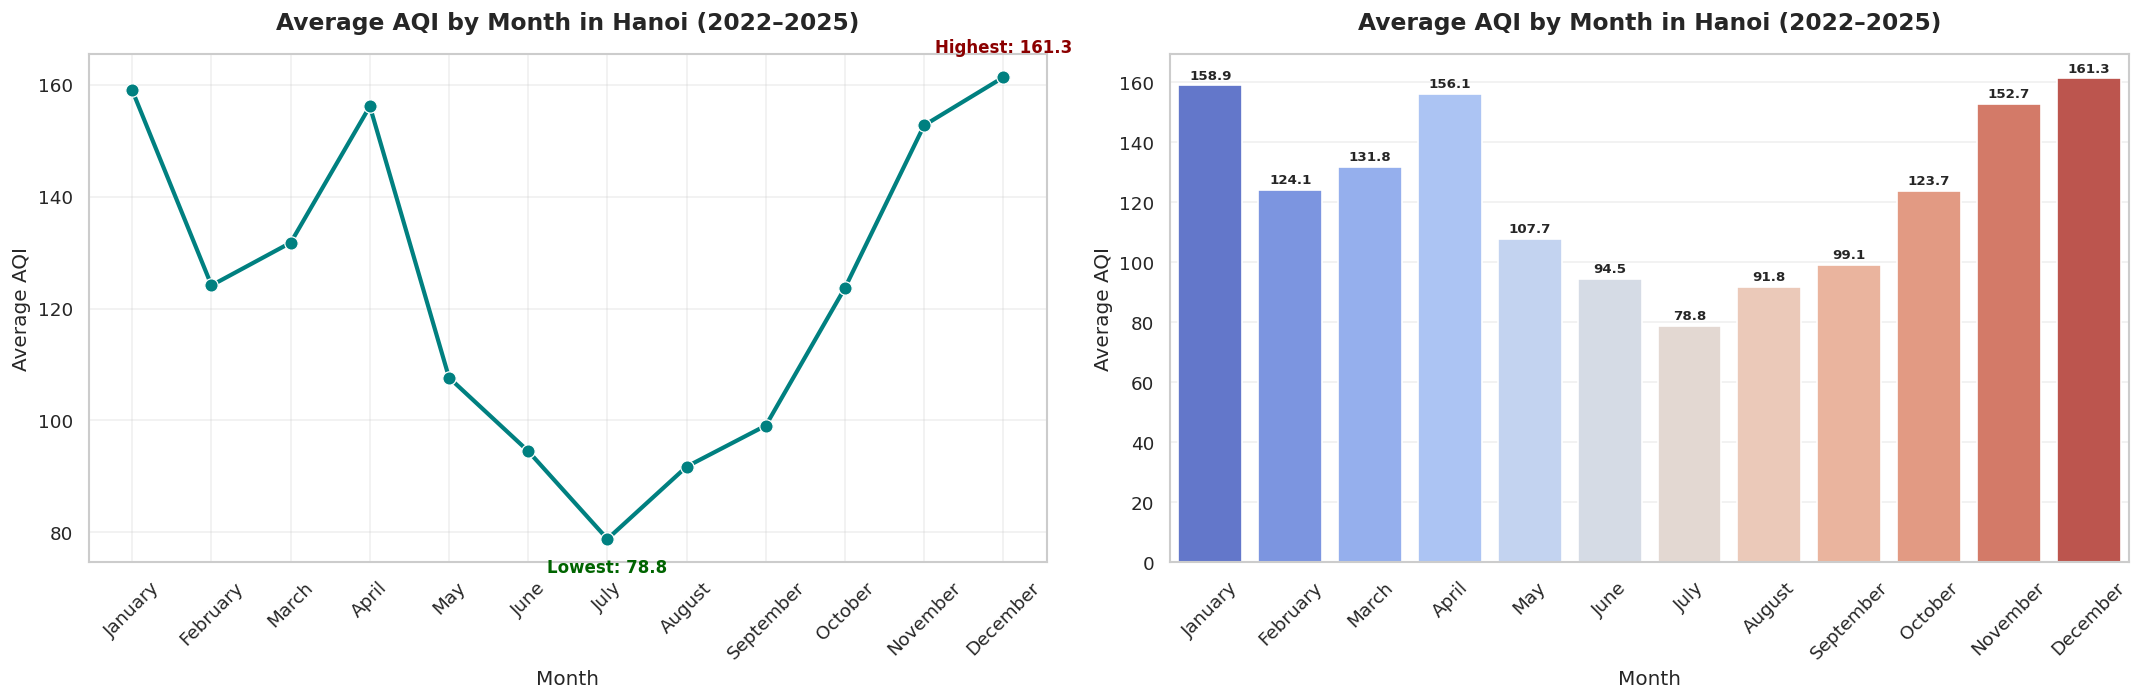

In [ ]:
monthly_plot = monthly_stats.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

line_plot(
    data=monthly_plot, x='month_name', y='mean',
    title='Average AQI by Month in Hanoi (2022–2025)',
    xlabel='Month', ylabel='Average AQI',
    color='teal', ax=axes[0]
)

max_idx = monthly_plot['mean'].idxmax()
min_idx = monthly_plot['mean'].idxmin()

axes[0].annotate(f'Highest: {monthly_plot["mean"].max():.1f}',
                xy=(max_idx, monthly_plot['mean'].max()),
                xytext=(0, 15), textcoords='offset points',
                ha='center', fontsize=10, fontweight='bold', color='darkred')
axes[0].annotate(f'Lowest: {monthly_plot["mean"].min():.1f}',
                xy=(min_idx, monthly_plot['mean'].min()),
                xytext=(0, -20), textcoords='offset points',
                ha='center', fontsize=10, fontweight='bold', color='darkgreen')

axes[0].tick_params(axis='x', rotation=45)

bar_plot(
    data=monthly_plot, x='month_name', y='mean',
    title='Average AQI by Month in Hanoi (2022–2025)',
    xlabel='Month', ylabel='Average AQI',
    palette='coolwarm', ax=axes[1]
)

for i, (_, row) in enumerate(monthly_plot.iterrows()):
    axes[1].text(i, row['mean'] + 1.2, f'{row["mean"]:.1f}',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')

axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
monthly_year_pivot = df_merged.pivot_table(
    values='AQI', index='month_name', columns='year', aggfunc='mean'
).round(1)

monthly_year_pivot.index = pd.CategoricalIndex(
    monthly_year_pivot.index, categories=MONTH_ORDER, ordered=True
)
monthly_year_pivot = monthly_year_pivot.sort_index()

print('=== Monthly Average AQI by Year ===')
display(monthly_year_pivot.style.background_gradient(cmap='YlOrRd', axis=None))

=== Monthly Average AQI by Year ===


year,2022,2023,2024,2025
month_name,,,,
January,153.100000,168.800000,135.500000,176.100000
February,142.500000,125.700000,96.800000,132.600000
March,117.500000,136.900000,130.200000,142.500000
April,145.500000,125.200000,187.000000,166.700000
May,113.900000,102.300000,91.400000,123.000000
June,94.200000,92.200000,82.500000,109.300000
July,83.200000,84.700000,68.500000,nan
August,84.200000,93.500000,97.500000,nan
September,116.300000,99.600000,81.400000,nan


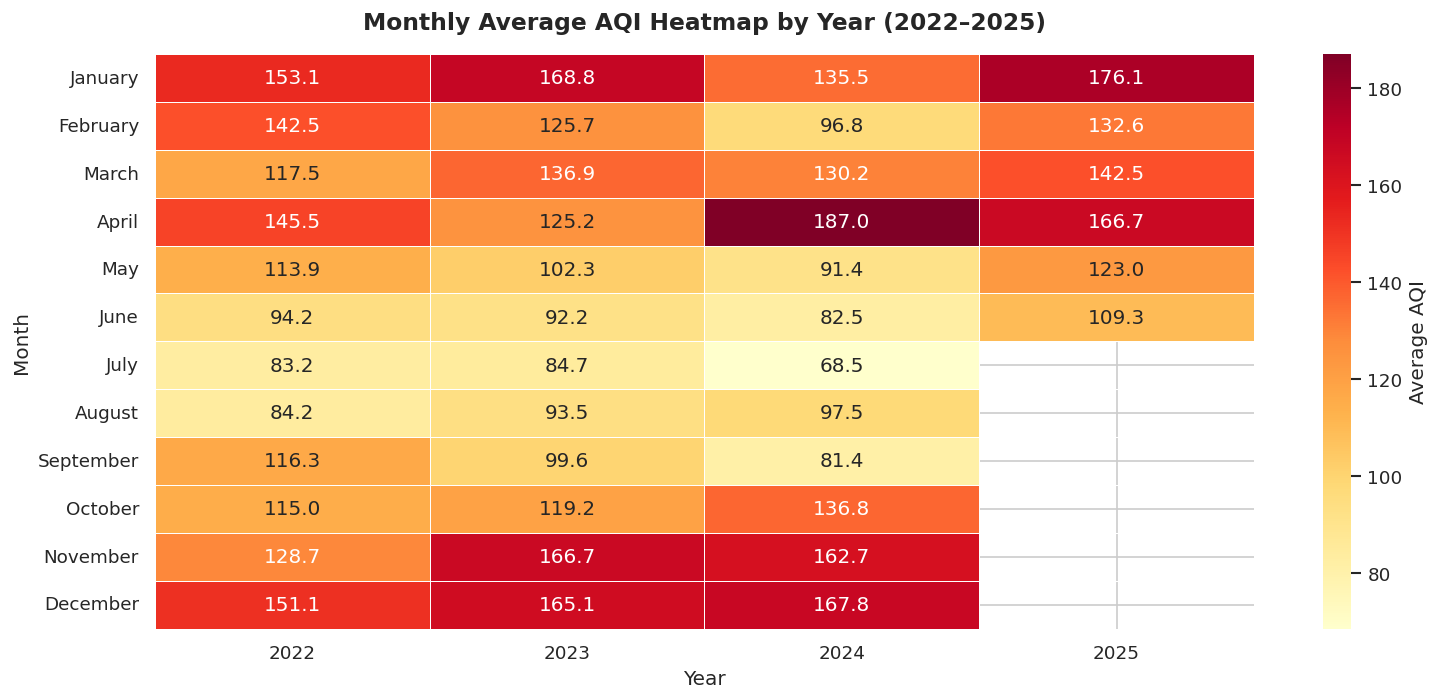

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(
    monthly_year_pivot, annot=True, fmt='.1f', cmap='YlOrRd',
    linewidths=0.5, cbar_kws={'label': 'Average AQI'}, ax=ax
)
ax.set_title('Monthly Average AQI Heatmap by Year (2022–2025)', fontweight='bold', pad=15)
ax.set_xlabel('Year')
ax.set_ylabel('Month')
plt.tight_layout()
plt.show()

In [ ]:
seasonal_stats = df_merged.groupby('season')['AQI'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
seasonal_stats = seasonal_stats.reindex(['Spring', 'Summer', 'Autumn', 'Winter'])

print('=== Seasonal AQI Statistics ===')
display(seasonal_stats.style.background_gradient(cmap='viridis', subset=['mean']))

=== Seasonal AQI Statistics ===


,mean,median,std,min,max
season,,,,,
Spring,131.580000,121.000000,62.140000,21.000000,500.000000
Summer,88.910000,82.000000,35.660000,4.000000,273.000000
Autumn,125.150000,112.000000,56.770000,12.000000,487.000000
Winter,147.220000,149.000000,54.770000,21.000000,500.000000


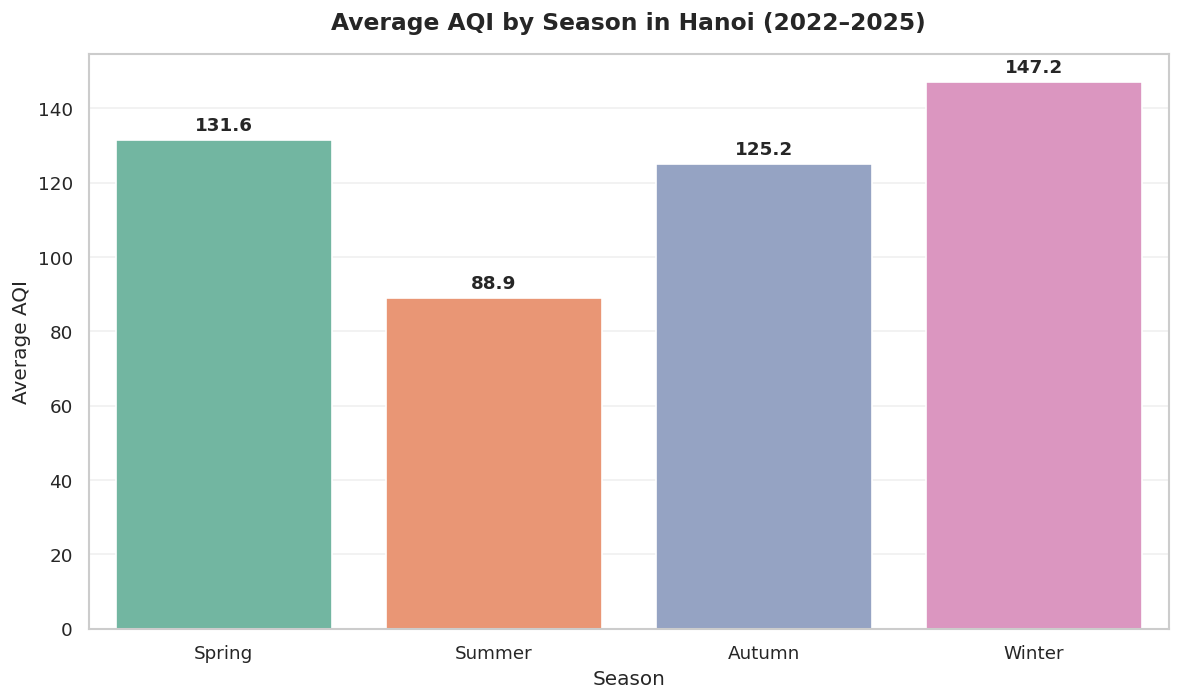

In [ ]:
seasonal_plot = seasonal_stats.reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
bar_plot(
    data=seasonal_plot, x='season', y='mean',
    title='Average AQI by Season in Hanoi (2022–2025)',
    xlabel='Season', ylabel='Average AQI',
    palette='Set2', ax=ax
)

for i, (_, row) in enumerate(seasonal_plot.iterrows()):
    ax.text(i, row['mean'] + 1.5, f'{row["mean"]:.1f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.show()

## 12.1 Insights — Seasonal AQI Patterns

### Monthly AQI Ranking

| Rank | Month | Mean AQI | Season |
|------|-------|----------:|--------|
| 1 (Highest) | December | 161.3 | Winter |
| 2 | January | 158.9 | Winter |
| 3 | April | 156.1 | Spring Transition |
| 12 (Lowest) | July | 78.8 | Summer |

---

### Key Observations

The analysis reveals a clear and consistent seasonal pattern in Hanoi’s air quality between 2022 and 2025.

- The most polluted months are **December (161.3)**, **January (158.9)**, and **April (156.1)**, which mainly occur during the winter and early spring periods.
- The cleanest months are **July (78.8)**, **August (91.8)**, and **June (94.5)**, corresponding to the summer season.
- AQI levels generally increase during the cool and dry months, while pollution decreases significantly during the hot and rainy months.
- This seasonal variation suggests that meteorological conditions strongly influence pollutant accumulation and atmospheric dispersion in Hanoi.

---

### Meteorological Interpretation

Hanoi’s seasonal AQI behavior is closely associated with regional weather and atmospheric conditions.

#### Winter and Early Spring (December–March)

During winter and early spring, AQI levels increase substantially due to several environmental factors:

- **Temperature inversions** trap pollutants near the ground surface, preventing vertical air circulation.
- Reduced wind speed and dry weather conditions limit pollutant dispersion and dilution.
- Increased emissions from transportation, industrial activities, and residential energy consumption contribute to higher pollution concentrations.

#### Summer Season (June–September)

During summer, AQI values decrease significantly because:

- Heavy rainfall removes airborne particulate matter through atmospheric cleansing processes.
- Stronger atmospheric convection improves pollutant dispersion.
- Oceanic wind systems bring cleaner air masses into the Hanoi region.

#### Transition Periods (April–May and October–November)

Transition months generally show moderate AQI levels as weather conditions gradually shift between the dry and rainy seasons.

---

### Answer to Research Question 2 (Q2)

Hanoi’s AQI demonstrates a distinct and recurring seasonal cycle throughout the 2022–2025 observation period. Air pollution reaches its highest levels during the cool and dry winter months, peaking in **December with an average AQI of 161.3**, while the lowest pollution levels occur during the rainy summer season, reaching a minimum in **July with an average AQI of 78.8**.

These seasonal fluctuations are primarily influenced by meteorological factors such as temperature inversions, rainfall intensity, atmospheric convection, and regional wind patterns. The findings indicate that seasonal weather conditions play a major role in shaping air quality variations in Hanoi.